# Phase 2: Surface relaxation

Same as random deposition, except that a landed atom checks its two neighbouring columns and rolls into a lower one. If both neighbours are lower it picks one at random. The boundaries are periodic: column N-1 sits next to column 0.

This local smoothing changes how roughness behaves on large scales:
* W grows as t^(1/4) instead of t^(1/2). This is the Edwards-Wilkinson universality class.
* W **saturates**. Once height information has spread across the whole substrate, the width stops growing. The plateau scales as W_sat ~ L^(1/2) and is reached after a time t_x ~ L^2.

In [1]:
# Setup: works locally (run from notebooks/) and in Google Colab.
# In Colab the project code must be available: it is cloned from GitHub if that repo exists,
# otherwise copy the project folder to Google Drive as MyDrive/thin_film_growth.
import os, subprocess, sys
if "google.colab" in sys.modules and not os.path.isdir("src/thin_film"):
    repo = "https://github.com/nhamhhung/thin-film-growth.git"
    if subprocess.run(["git", "clone", "-q", repo, "/content/thin_film_growth"]).returncode == 0:
        os.chdir("/content/thin_film_growth")
    else:
        from google.colab import drive
        drive.mount("/content/drive")
        os.chdir("/content/drive/MyDrive/thin_film_growth")
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "numba"], check=True)
root = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(root, "src"))

import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML

In [2]:
from thin_film import random_deposition as rd, surface_relaxation as sr
from thin_film.roughness import fit_growth_exponent
from thin_film.plotting import plot_roughness_loglog, plot_surface

## 1. The rule, step by step
The kernel takes pre-drawn random numbers, so the plain-Python and Numba versions see identical inputs and must build identical films.

In [3]:
h = np.array([3, 5, 1, 1, 4], dtype=np.int64)
sr.relax_deposit_python(h, np.array([1]), np.array([0.7]))   # lands on column 1 (height 5); both neighbours lower, coin 0.7 -> right
h

array([3, 5, 2, 1, 4])

## 2. Profiles: random deposition vs relaxation (same random landing sites)

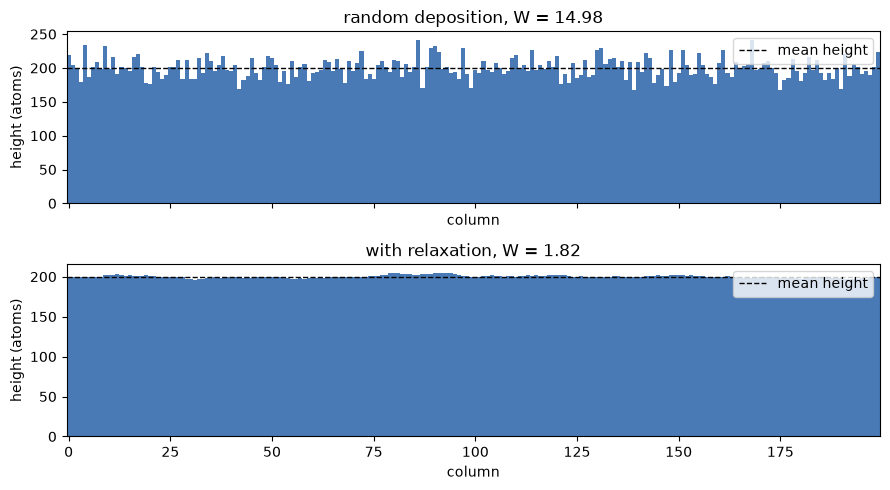

In [4]:
rng = np.random.default_rng(0)
cols, coins = rng.integers(200, size=200 * 200), rng.random(200 * 200)
h_rd = np.bincount(cols, minlength=200)
h_sr = np.zeros(200, np.int64); sr.relax_deposit_numba(h_sr, cols, coins)
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
plot_surface(h_rd, ax=axes[0], title=f"random deposition, W = {h_rd.std():.2f}")
plot_surface(h_sr, ax=axes[1], title=f"with relaxation, W = {h_sr.std():.2f}")
fig.tight_layout(); plt.show()

## 3. Growth exponent and saturation

beta (L=200, t <= 100 ML) = 0.248 +/- 0.003   (theory 0.25)


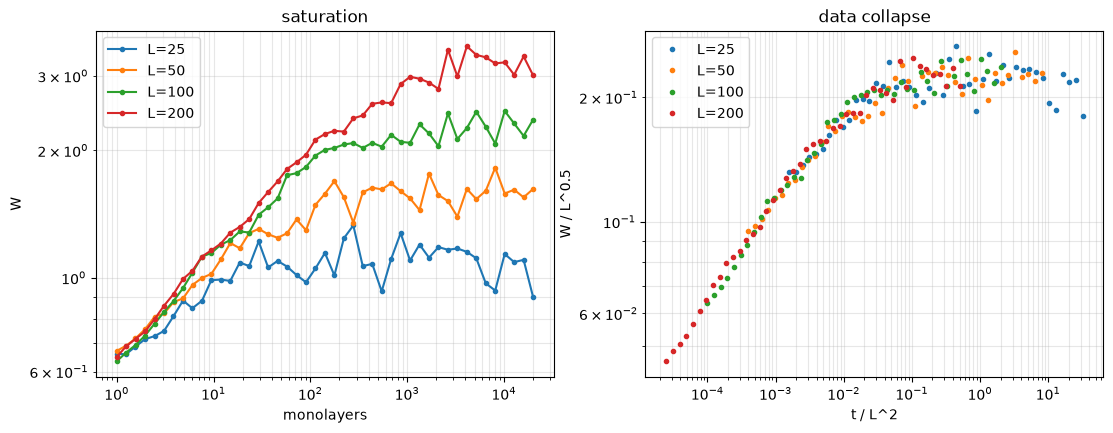

In [5]:
curves = {L: sr.run_ensemble(sr.RelaxSettings(n_columns=L, n_monolayers=20000, n_runs=20)) for L in (25, 50, 100, 200)}
early = curves[200][curves[200]["monolayers"] <= 100]
beta, err = fit_growth_exponent(early["monolayers"], early["roughness_mean"])
print(f"beta (L=200, t <= 100 ML) = {beta:.3f} +/- {err:.3f}   (theory 0.25)")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for L, df in curves.items():
    axes[0].loglog(df["monolayers"], df["roughness_mean"], "o-", ms=3, label=f"L={L}")
    axes[1].loglog(df["monolayers"] / L**2, df["roughness_mean"] / L**0.5, "o", ms=3, label=f"L={L}")
axes[0].set(xlabel="monolayers", ylabel="W", title="saturation"); axes[1].set(xlabel="t / L^2", ylabel="W / L^0.5", title="data collapse")
for ax in axes: ax.legend(); ax.grid(True, which="both", alpha=.3)
plt.show()

When the axes are rescaled by L^2 (time) and L^0.5 (width), the curves for all four sizes fall onto one line. This is the Family-Vicsek scaling form, and it confirms z = 2 and alpha = 1/2.

## 4. Why Numba
Each atom's destination depends on the current surface, so atoms have to be processed one at a time in a loop. `@njit` compiles that loop to machine code.

In [6]:
rng = np.random.default_rng(1); n = 200_000
cols, coins = rng.integers(200, size=n), rng.random(n)
sr.relax_deposit_numba(np.zeros(200, np.int64), cols[:5], coins[:5])  # compile once
for name, k in [("python", sr.relax_deposit_python), ("numba", sr.relax_deposit_numba)]:
    h = np.zeros(200, np.int64); t0 = time.perf_counter(); k(h, cols, coins); dt = time.perf_counter() - t0
    print(f"{name:7s} {dt*1e3:8.2f} ms   ({n/dt:,.0f} atoms/s)")

python     70.54 ms   (2,835,135 atoms/s)
numba       0.61 ms   (326,264,268 atoms/s)


## Takeaway
One local rule, "roll downhill to a neighbour", is enough to make the surface smooth itself and saturate. Phase 3 replaces this always-on rule with hopping that depends on temperature.